# Sistemas Inteligentes · Sesiones 06 y 07
## Lógica difusa y algoritmos genéticos

**Integrantes:** ______________________  **Grupo / sección:** ________  **Fecha:** ________

Este notebook contiene los dos casos del trabajo grupal, ejecutables de principio a fin: **Parte A** (sistema de inferencia difusa Mamdani para el riesgo académico) y **Parte B** (algoritmo genético para la selección de proyectos con presupuesto limitado). Solo usa **NumPy** y **Matplotlib** (más `time` y `dataclasses` de la biblioteca estándar); los operadores genéticos y la inferencia difusa están programados directamente. Las semillas están fijas, por lo que los resultados son reproducibles (los tiempos dependen del equipo).

> El índice de riesgo que produce la Parte A **no es la probabilidad** de desaprobar: es un valor 0-100 obtenido con reglas difusas.

In [ ]:
from __future__ import annotations

import time
from dataclasses import dataclass, replace

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("NumPy", np.__version__)

NumPy 2.4.4


# Parte A · Lógica difusa: riesgo académico

## A.1 Conjuntos difusos y funciones de pertenencia
Se usan funciones triangulares y trapezoidales (las hombreras se obtienen con `a = b` o `c = d`). Los universos de discurso son: asistencia 0-100 %, promedio 0-20, estudio semanal 0-30 h y riesgo 0-100. Los parámetros son **decisiones de diseño del grupo**; se justifican en la tabla y pueden modificarse (ver A.6).

| Variable | Etiqueta | Función | Parámetros | Justificación |
|---|---|---|---|---|
| Asistencia (%) | Baja | Trapezoidal | (0, 0, 40, 60) | Hombro izquierdo: por debajo de 40 % la asistencia es claramente deficiente (pertenencia 1) y deja de serlo gradualmente hasta 60 %. |
|  | Media | Triangular | (40, 65, 85) | Pico en 65 %, valor intermedio entre los extremos; se traslapa con Baja (40-60) y con Alta (75-85). |
|  | Alta | Trapezoidal | (75, 90, 100, 100) | Hombro derecho: plena desde 90 %; empieza a ser alta desde 75 %. |
| Promedio (0-20) | Bajo | Trapezoidal | (0, 0, 6, 11) | En la escala vigesimal 11 suele ser la nota mínima aprobatoria; por encima de 11 el promedio deja de ser bajo. |
|  | Regular | Triangular | (8, 12, 16) | Pico en 12, cercano al umbral aprobatorio; base amplia (8-16) para desempeños intermedios. |
|  | Alto | Trapezoidal | (14, 17, 20, 20) | Plena desde 17; desde 14 comienza a considerarse alto. |
| Estudio semanal (0-30 h) | Pocas | Trapezoidal | (0, 0, 4, 10) | Hasta 4 h/semana es claramente poco; deja de serlo hacia las 10 h. |
|  | Moderadas | Triangular | (6, 15, 24) | Pico en 15 h/semana, punto medio del dominio, con base amplia. |
|  | Muchas | Trapezoidal | (18, 24, 30, 30) | Plena desde 24 h/semana; comienza a ser mucha desde 18 h. |
| Riesgo (0-100) | Bajo | Trapezoidal | (0, 0, 20, 45) | Extremo inferior de la escala; se traslapa con Medio entre 25 y 45. |
|  | Medio | Triangular | (25, 50, 75) | Centrado en 50, con traslapes a ambos lados para suavizar la transición. |
|  | Alto | Trapezoidal | (55, 80, 100, 100) | Extremo superior; se traslapa con Medio entre 55 y 75. |

In [ ]:
def trapezoidal(x, a: float, b: float, c: float, d: float):
    """Función de pertenencia trapezoidal con a <= b <= c <= d.
    Si a == b (o c == d) se obtiene un hombro vertical izquierdo (o derecho)."""
    if not (a <= b <= c <= d):
        raise ValueError(f"Parámetros inválidos: se exige a<=b<=c<=d, recibido {(a, b, c, d)}")
    es_escalar = np.isscalar(x)
    x = np.atleast_1d(np.asarray(x, dtype=float))
    y = np.zeros_like(x)
    if b > a:
        m = (x >= a) & (x < b)
        y[m] = (x[m] - a) / (b - a)
    y[(x >= b) & (x <= c)] = 1.0
    if d > c:
        m = (x > c) & (x <= d)
        y[m] = (d - x[m]) / (d - c)
    return float(y[0]) if es_escalar else y


def triangular(x, a: float, b: float, c: float):
    """Función triangular = trapecio con meseta de un solo punto (b == c)."""
    return trapezoidal(x, a, b, b, c)


# (tipo, parámetros) por variable y etiqueta
PARAMETROS: dict[str, dict[str, tuple[str, tuple[float, ...]]]] = {
    "asistencia": {"Baja": ("trap", (0, 0, 40, 60)),
                   "Media": ("tri", (40, 65, 85)),
                   "Alta": ("trap", (75, 90, 100, 100))},
    "promedio":   {"Bajo": ("trap", (0, 0, 6, 11)),
                   "Regular": ("tri", (8, 12, 16)),
                   "Alto": ("trap", (14, 17, 20, 20))},
    "estudio":    {"Pocas": ("trap", (0, 0, 4, 10)),
                   "Moderadas": ("tri", (6, 15, 24)),
                   "Muchas": ("trap", (18, 24, 30, 30))},
    "riesgo":     {"Bajo": ("trap", (0, 0, 20, 45)),
                   "Medio": ("tri", (25, 50, 75)),
                   "Alto": ("trap", (55, 80, 100, 100))},
}
RANGOS: dict[str, tuple[float, float]] = {
    "asistencia": (0, 100), "promedio": (0, 20), "estudio": (0, 30), "riesgo": (0, 100)}
UNIDADES = {"asistencia": "Asistencia (%)", "promedio": "Promedio (0-20)",
            "estudio": "Estudio semanal (horas)", "riesgo": "Riesgo académico (0-100)"}
X_RIESGO = np.linspace(0, 100, 1001)  # universo discretizado de la salida


def pertenencia(variable: str, etiqueta: str, x, parametros=PARAMETROS):
    tipo, p = parametros[variable][etiqueta]
    return triangular(x, *p) if tipo == "tri" else trapezoidal(x, *p)


print("Funciones de pertenencia definidas. Prueba: asistencia 60 % ->",
      {e: round(pertenencia("asistencia", e, 60), 3) for e in PARAMETROS["asistencia"]})

Funciones de pertenencia definidas. Prueba: asistencia 60 % -> {'Baja': 0.0, 'Media': 0.8, 'Alta': 0.0}


### A.2 Gráficas de los conjuntos de entrada y salida

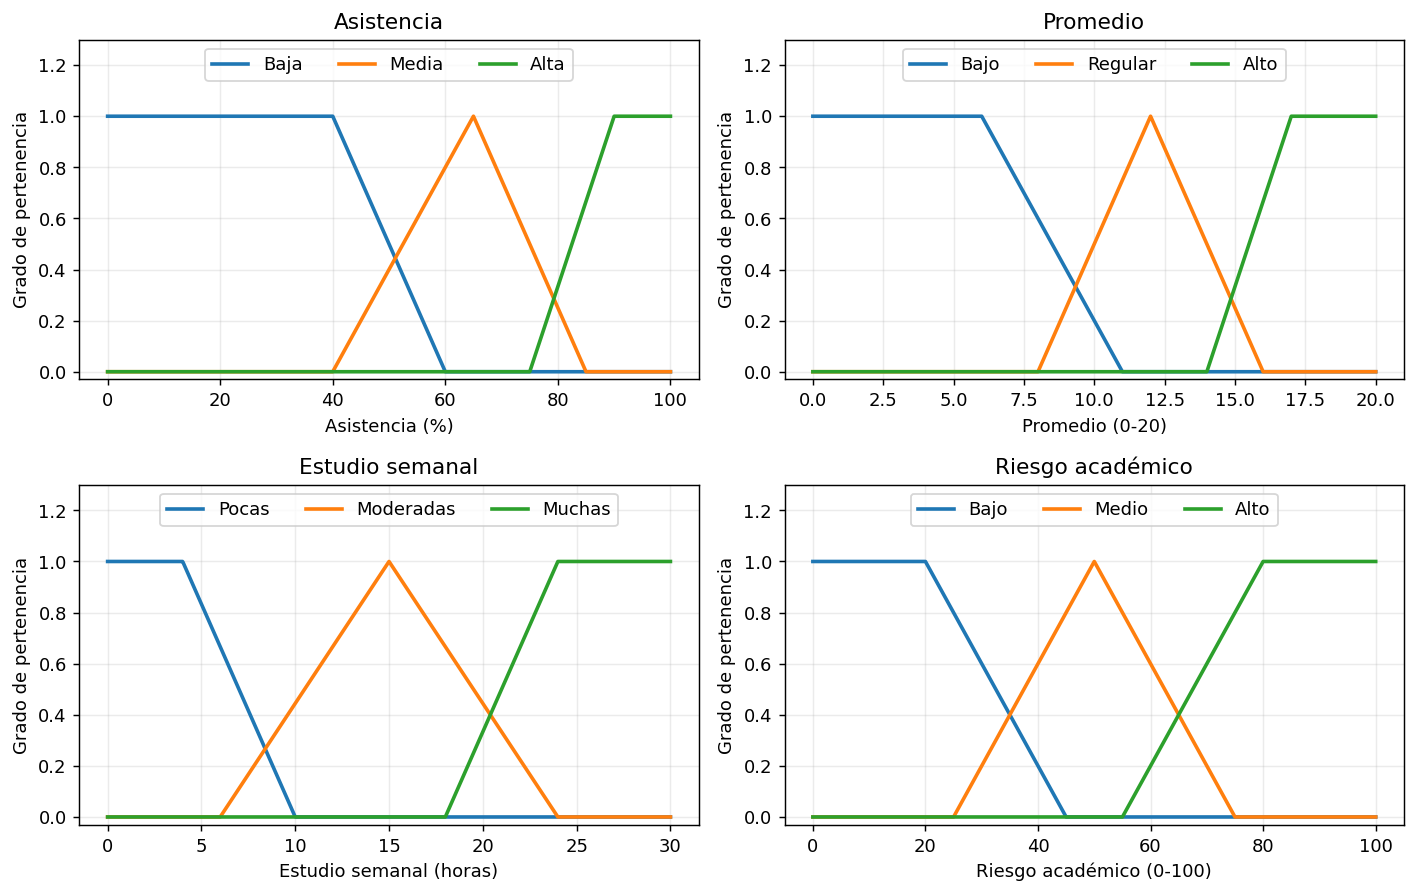

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
fig.set_label("funciones_pertenencia")
for ax, variable in zip(ejes.ravel(), PARAMETROS):
    lo, hi = RANGOS[variable]
    x = np.linspace(lo, hi, 1001)
    for etiqueta in PARAMETROS[variable]:
        ax.plot(x, pertenencia(variable, etiqueta, x), linewidth=2, label=etiqueta)
    ax.set_title(UNIDADES[variable].split(" (")[0])
    ax.set_xlabel(UNIDADES[variable])
    ax.set_ylabel("Grado de pertenencia")
    ax.set_ylim(-0.03, 1.3)
    ax.legend(loc="upper center", ncol=3)
fig.tight_layout()
plt.show()

## A.3 Base de reglas SI–ENTONCES
Se definieron **18 reglas** a mano, agrupadas por la conclusión: riesgo alto cuando coinciden varios factores desfavorables, riesgo bajo cuando coinciden favorables, riesgo medio en situaciones intermedias y en los **casos conflictivos** (señales opuestas, como asistir mucho pero rendir mal). Cada regla usa dos antecedentes unidos con AND. La celda siguiente comprueba que la base **no deja huecos**: para cualquier combinación de entradas se activa al menos una regla.

In [ ]:
@dataclass(frozen=True)
class Regla:
    id: str
    antecedentes: dict          # {variable: etiqueta}, unidos con AND
    consecuente: str            # etiqueta de riesgo

    def texto(self) -> str:
        cond = " Y ".join(f"{v} es {e}" for v, e in self.antecedentes.items())
        return f"{self.id}: SI {cond} ENTONCES riesgo es {self.consecuente}"


# (asistencia, promedio, estudio, riesgo); None = la variable no interviene en la regla
TABLA_REGLAS = [
    # --- Riesgo ALTO: varios factores desfavorables a la vez
    ("Baja",  "Bajo",    None,        "Alto"),
    ("Baja",  None,      "Pocas",     "Alto"),
    (None,    "Bajo",    "Pocas",     "Alto"),
    ("Media", "Bajo",    None,        "Alto"),
    # --- Riesgo BAJO: factores favorables a la vez
    ("Alta",  "Alto",    None,        "Bajo"),
    (None,    "Alto",    "Muchas",    "Bajo"),
    ("Alta",  "Regular", None,        "Bajo"),
    ("Media", "Alto",    None,        "Bajo"),
    # --- Riesgo MEDIO: situaciones intermedias
    ("Media", "Regular", None,        "Medio"),
    (None,    "Regular", "Moderadas", "Medio"),
    ("Media", None,      "Moderadas", "Medio"),
    ("Baja",  "Regular", None,        "Medio"),
    # --- Casos conflictivos (señales opuestas) -> riesgo MEDIO
    ("Alta",  "Bajo",    None,        "Medio"),   # asiste pero rinde mal
    ("Baja",  "Alto",    None,        "Medio"),   # rinde bien pero casi no asiste
    (None,    "Bajo",    "Muchas",    "Medio"),   # estudia mucho y aun así rinde mal
    (None,    "Alto",    "Pocas",     "Medio"),   # rinde bien con poco estudio
    ("Alta",  None,      "Pocas",     "Medio"),   # asiste pero casi no estudia
    ("Baja",  None,      "Muchas",    "Medio"),   # estudia mucho pero casi no asiste
]


def construir_reglas(tabla) -> list[Regla]:
    reglas = []
    for i, (a, p, e, salida) in enumerate(tabla, start=1):
        ant = {k: v for k, v in (("asistencia", a), ("promedio", p), ("estudio", e)) if v}
        reglas.append(Regla(f"R{i}", ant, salida))
    return reglas


REGLAS: list[Regla] = construir_reglas(TABLA_REGLAS)
for r in REGLAS:
    print(r.texto())
print(f"\nTotal de reglas: {len(REGLAS)}")

R1: SI asistencia es Baja Y promedio es Bajo ENTONCES riesgo es Alto
R2: SI asistencia es Baja Y estudio es Pocas ENTONCES riesgo es Alto
R3: SI promedio es Bajo Y estudio es Pocas ENTONCES riesgo es Alto
R4: SI asistencia es Media Y promedio es Bajo ENTONCES riesgo es Alto
R5: SI asistencia es Alta Y promedio es Alto ENTONCES riesgo es Bajo
R6: SI promedio es Alto Y estudio es Muchas ENTONCES riesgo es Bajo
R7: SI asistencia es Alta Y promedio es Regular ENTONCES riesgo es Bajo
R8: SI asistencia es Media Y promedio es Alto ENTONCES riesgo es Bajo
R9: SI asistencia es Media Y promedio es Regular ENTONCES riesgo es Medio
R10: SI promedio es Regular Y estudio es Moderadas ENTONCES riesgo es Medio
R11: SI asistencia es Media Y estudio es Moderadas ENTONCES riesgo es Medio
R12: SI asistencia es Baja Y promedio es Regular ENTONCES riesgo es Medio
R13: SI asistencia es Alta Y promedio es Bajo ENTONCES riesgo es Medio
R14: SI asistencia es Baja Y promedio es Alto ENTONCES riesgo es Medio
R15:

## A.4 Inferencia Mamdani y desfusificación
Etapas implementadas en `inferir`:
1. **Fusificación:** grado de pertenencia de cada entrada a cada etiqueta.
2. **Conjunción (AND):** mínimo de los grados de los antecedentes de la regla = *fuerza de activación*.
3. **Implicación:** recorte (mínimo) del conjunto de salida de la regla a su fuerza de activación.
4. **Agregación:** máximo, punto a punto, de las salidas recortadas de todas las reglas.
5. **Desfusificación por centroide:** `Σ x·μ(x) / Σ μ(x)` sobre un universo de 1001 puntos.

**Categoría final:** etiqueta de salida con mayor pertenencia del valor desfusificado (en empate, la más alta). Equivale a Bajo si el riesgo es menor que 35, Medio entre 35 y 65, y Alto si es mayor que 65. Las entradas se **validan**: fuera del dominio se lanza `ValueError`.

In [ ]:
@dataclass
class ResultadoDifuso:
    entradas: dict
    grados: dict
    activadas: list          # [(Regla, activación)]
    agregada: np.ndarray
    valor: float
    categoria: str
    pert_salida: dict        # pertenencia del valor desfusificado a Bajo/Medio/Alto


def validar_entradas(asistencia: float, promedio: float, estudio: float) -> None:
    for nombre, valor in (("asistencia", asistencia), ("promedio", promedio), ("estudio", estudio)):
        lo, hi = RANGOS[nombre]
        if not isinstance(valor, (int, float, np.integer, np.floating)) or np.isnan(valor):
            raise TypeError(f"{nombre}: se esperaba un número, recibido {valor!r}")
        if not lo <= valor <= hi:
            raise ValueError(f"{nombre}={valor} fuera del dominio [{lo}, {hi}]")


def fuzzificar(entradas: dict, parametros=PARAMETROS) -> dict:
    """Etapa 1: grado de pertenencia de cada entrada a cada etiqueta."""
    return {v: {e: float(pertenencia(v, e, x, parametros)) for e in parametros[v]}
            for v, x in entradas.items()}


def activacion(regla: Regla, grados: dict) -> float:
    """Etapa 2: conjunción AND = mínimo de los grados del antecedente."""
    return min(grados[v][e] for v, e in regla.antecedentes.items())


def centroide(x: np.ndarray, mu: np.ndarray) -> float:
    """Etapa 5: centroide discreto  sum(x*mu) / sum(mu)  sobre un universo uniforme."""
    area = mu.sum()
    return float((x * mu).sum() / area) if area > 0 else float("nan")


def inferir(asistencia: float, promedio: float, estudio: float,
            reglas: list[Regla] | None = None, parametros=PARAMETROS) -> ResultadoDifuso:
    """Inferencia Mamdani: AND=mín, implicación=recorte (mín), agregación=máx, defuzz=centroide."""
    validar_entradas(asistencia, promedio, estudio)
    reglas = REGLAS if reglas is None else reglas
    entradas = {"asistencia": asistencia, "promedio": promedio, "estudio": estudio}
    grados = fuzzificar(entradas, parametros)
    agregada = np.zeros_like(X_RIESGO)
    activadas = []
    for regla in reglas:
        a = activacion(regla, grados)
        if a > 0:
            recorte = np.minimum(a, pertenencia("riesgo", regla.consecuente, X_RIESGO, parametros))  # implicación
            agregada = np.maximum(agregada, recorte)                                                # agregación
            activadas.append((regla, a))
    valor = centroide(X_RIESGO, agregada)
    if np.isnan(valor):
        raise RuntimeError("Ninguna regla se activó: la base de reglas no cubre esta entrada")
    pert = {e: float(pertenencia("riesgo", e, valor, parametros)) for e in parametros["riesgo"]}
    categoria = max(reversed(list(pert)), key=pert.get)   # mayor pertenencia; en empate, la categoría más alta
    return ResultadoDifuso(entradas, grados, activadas, agregada, valor, categoria, pert)


# Verificación de cobertura: toda combinación de entradas debe activar al menos una regla
cobertura_min = min(
    max(activacion(r, fuzzificar({"asistencia": a, "promedio": p, "estudio": e})) for r in REGLAS)
    for a in np.arange(0, 101, 2.5) for p in np.arange(0, 20.1, 0.5) for e in np.arange(0, 30.1, 1.0))
print(f"Cobertura: la mayor activación mínima sobre la malla de entradas es {cobertura_min:.3f} (> 0 => sin huecos)")

Cobertura: la mayor activación mínima sobre la malla de entradas es 0.333 (> 0 => sin huecos)


## A.5 Evaluación de los cinco casos (E01–E05) y de tres casos adicionales (X1–X3)

In [ ]:
CASOS: dict[str, tuple[float, float, float]] = {
    "E01": (95, 17, 20), "E02": (72, 13, 10), "E03": (48, 9, 4),
    "E04": (85, 11, 8),  "E05": (60, 16, 15),
}
CASOS_EXTRA: dict[str, tuple[float, float, float]] = {
    "X1": (98, 19, 28),   # caso favorable en las tres variables
    "X2": (35, 6, 2),     # caso desfavorable en las tres variables
    "X3": (90, 8, 25),    # conflictivo: asiste y estudia mucho, pero promedio bajo
}
TODOS = {**CASOS, **CASOS_EXTRA}
RES = {k: inferir(*v) for k, v in TODOS.items()}

print(f"{'Caso':<5}{'Asist.':>7}{'Prom.':>7}{'Horas':>7}{'Riesgo':>9}  {'Categoría':<10}{'Reglas activadas':>17}")
for k, r in RES.items():
    a, p, e = TODOS[k]
    print(f"{k:<5}{a:>7}{p:>7}{e:>7}{r.valor:>9.2f}  {r.categoria:<10}{len(r.activadas):>17}")

Caso  Asist.  Prom.  Horas   Riesgo  Categoría  Reglas activadas
E01       95     17     20    17.03  Bajo                      2
E02       72     13     10    50.00  Medio                     3
E03       48      9      4    71.56  Alto                      6
E04       85     11      8    29.42  Bajo                      3
E05       60     16     15    34.08  Bajo                      2
X1        98     19     28    17.03  Bajo                      2
X2        35      6      2    82.97  Alto                      3
X3        90      8     25    50.00  Medio                     2


In [ ]:
for k, r in RES.items():
    a, p, e = TODOS[k]
    print(f"=== {k}: asistencia={a} %, promedio={p}, estudio={e} h/sem ===")
    for var, dic in r.grados.items():
        no_cero = {et: round(g, 3) for et, g in dic.items() if g > 0}
        print(f"  Pertenencia {var:<10}: {no_cero}")
    print("  Reglas activadas :", ", ".join(f"{rg.id}->{rg.consecuente} ({act:.2f})" for rg, act in r.activadas))
    print(f"  Pertenencia del valor a Bajo/Medio/Alto: " + ", ".join(f"{et}={g:.2f}" for et, g in r.pert_salida.items()))
    print(f"  Riesgo (centroide) = {r.valor:.2f}  ->  categoría {r.categoria}\n")

=== E01: asistencia=95 %, promedio=17, estudio=20 h/sem ===
  Pertenencia asistencia: {'Alta': 1.0}
  Pertenencia promedio  : {'Alto': 1.0}
  Pertenencia estudio   : {'Moderadas': 0.444, 'Muchas': 0.333}
  Reglas activadas : R5->Bajo (1.00), R6->Bajo (0.33)
  Pertenencia del valor a Bajo/Medio/Alto: Bajo=1.00, Medio=0.00, Alto=0.00
  Riesgo (centroide) = 17.03  ->  categoría Bajo

=== E02: asistencia=72 %, promedio=13, estudio=10 h/sem ===
  Pertenencia asistencia: {'Media': 0.65}
  Pertenencia promedio  : {'Regular': 0.75}
  Pertenencia estudio   : {'Moderadas': 0.444}
  Reglas activadas : R9->Medio (0.65), R10->Medio (0.44), R11->Medio (0.44)
  Pertenencia del valor a Bajo/Medio/Alto: Bajo=0.00, Medio=1.00, Alto=0.00
  Riesgo (centroide) = 50.00  ->  categoría Medio

=== E03: asistencia=48 %, promedio=9, estudio=4 h/sem ===
  Pertenencia asistencia: {'Baja': 0.6, 'Media': 0.32}
  Pertenencia promedio  : {'Bajo': 0.4, 'Regular': 0.25}
  Pertenencia estudio   : {'Pocas': 1.0}
  Reglas 

### Salida agregada y centroide de cada caso

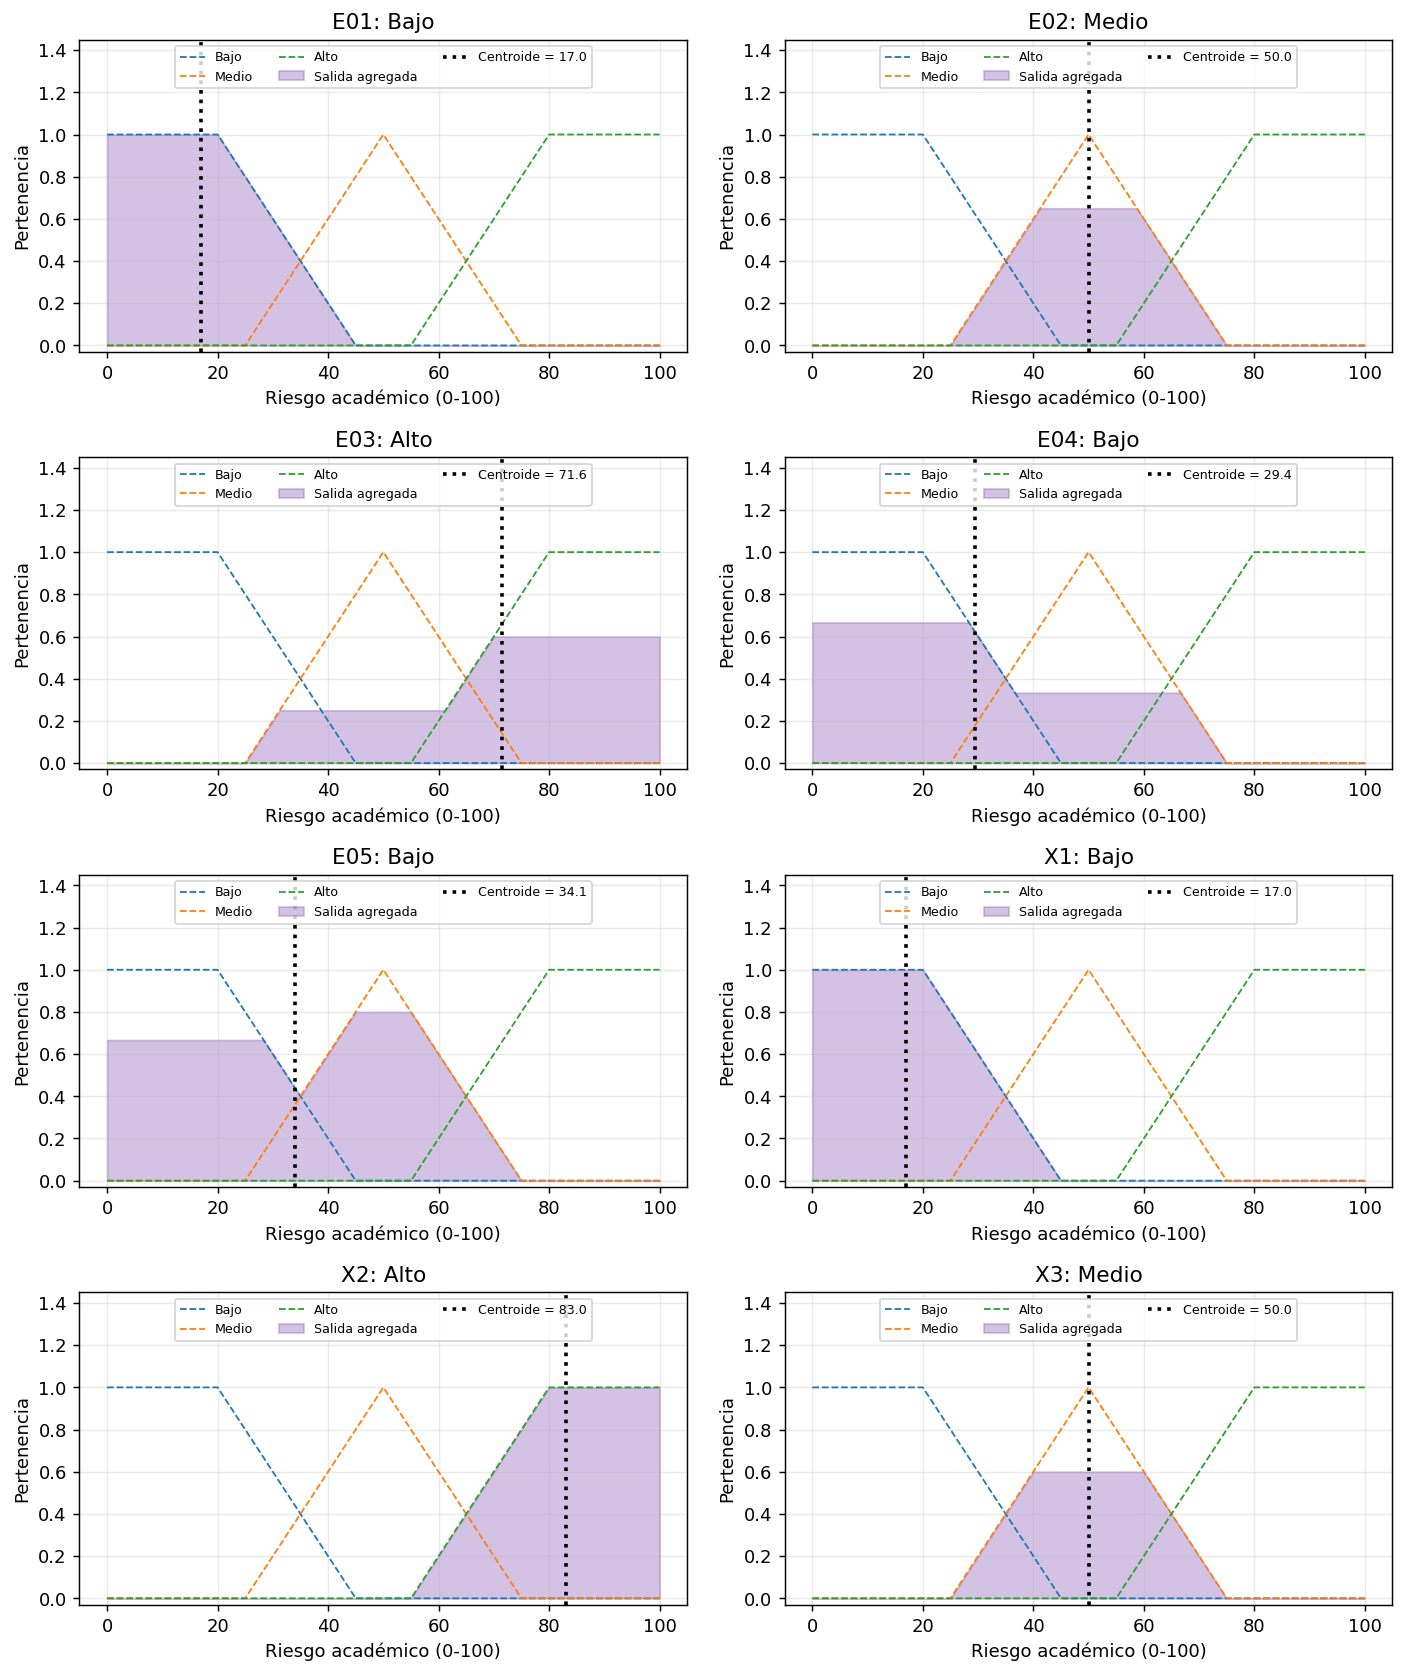

In [ ]:
fig, ejes = plt.subplots(4, 2, figsize=(11, 13))
fig.set_label("salida_agregada")
for ax, (k, r) in zip(ejes.ravel(), RES.items()):
    for et in PARAMETROS["riesgo"]:
        ax.plot(X_RIESGO, pertenencia("riesgo", et, X_RIESGO), "--", linewidth=1, label=et)
    ax.fill_between(X_RIESGO, r.agregada, alpha=0.4, color="tab:purple", label="Salida agregada")
    ax.axvline(r.valor, color="k", linestyle=":", linewidth=2, label=f"Centroide = {r.valor:.1f}")
    ax.set_title(f"{k}: {r.categoria}")
    ax.set_xlabel("Riesgo académico (0-100)")
    ax.set_ylabel("Pertenencia")
    ax.set_ylim(-0.03, 1.45)
    ax.legend(fontsize=7, loc="upper center", ncol=3)
fig.tight_layout()
plt.show()

### Interpretación de los resultados

- **E01 (95 %, 17, 20 h): riesgo 17.03 → Bajo.** Asistencia alta y promedio alto tienen pertenencia 1; el estudio es moderado/mucho en parte (0.44 y 0.33). Domina R5.

- **E02 (72 %, 13, 10 h): riesgo 50.00 → Medio.** Todas las entradas son intermedias (Media 0.65, Regular 0.75, Moderadas 0.44) y las tres reglas activadas concluyen Medio.

- **E03 (48 %, 9, 4 h): riesgo 71.56 → Alto.** Asistencia baja (0.6), promedio bajo (0.4) y pocas horas (1.0) activan cuatro reglas de riesgo alto; dos reglas de riesgo medio, con activación 0.25, solo suavizan el resultado.

- **E04 (85 %, 11, 8 h): riesgo 29.42 → Bajo, pero cerca de la frontera.** La asistencia alta (0.67) con promedio regular activa R7 (Bajo); las horas bajas activan R17 y R10 (Medio). Con pertenencia 0.62 a Bajo y 0.18 a Medio, la categoría depende de la regla de clasificación.

- **E05 (60 %, 16, 15 h): riesgo 34.08 → Bajo, también cerca de la frontera.** Promedio alto (0.67) empuja a Bajo (R8) y asistencia media con estudio moderado empuja a Medio (R11, 0.80). Pertenencia 0.44 a Bajo y 0.36 a Medio.

- **Casos propios.** X1 (98 %, 19, 28 h) favorable en todo: 17.03 → Bajo. X2 (35 %, 6, 2 h) desfavorable en todo: 82.97 → Alto. X3 (90 %, 8, 25 h) conflictivo, asiste y estudia mucho pero con promedio bajo: 50.00 → Medio, porque solo se activan las reglas conflictivas R13 y R15, ambas con consecuente Medio.

**Limitación.** Los casos E04 y E05 quedan cerca de la frontera Bajo/Medio (35); un pequeño cambio en un parámetro puede cambiar su categoría. La numeración **R1…R18** de las reglas activadas en cada caso corresponde a la tabla de A.3.

## A.6 Efecto de modificar una regla o una función de pertenencia

In [ ]:
# Variante 1: la regla conflictiva "asistencia Alta Y promedio Bajo" pasa de Medio a Alto
ID_CONFLICTIVA = next(r.id for r in REGLAS if r.antecedentes == {"asistencia": "Alta", "promedio": "Bajo"})
reglas_v1 = [replace(r, consecuente="Alto") if r.id == ID_CONFLICTIVA else r for r in REGLAS]
print(f"Variante 1 modifica {ID_CONFLICTIVA}: Medio -> Alto")

# Variante 2: ensanchar el conjunto "Promedio Bajo" (hombro hasta 8 y caída hasta 13)
parametros_v2 = {v: dict(d) for v, d in PARAMETROS.items()}
parametros_v2["promedio"]["Bajo"] = ("trap", (0, 0, 8, 13))

filas = []
for k, (a, p, e) in TODOS.items():
    base = RES[k].valor
    v1 = inferir(a, p, e, reglas=reglas_v1).valor
    v2 = inferir(a, p, e, parametros=parametros_v2).valor
    filas.append((k, base, v1, v2))

print(f"{'Caso':<5}{'Base':>8}{'V1: regla->Alto':>16}{'Δ':>8}{'V2: Prom.Bajo ancho':>22}{'Δ':>8}")
for k, b, v1, v2 in filas:
    print(f"{k:<5}{b:>8.2f}{v1:>16.2f}{v1 - b:>+8.2f}{v2:>22.2f}{v2 - b:>+8.2f}")

Variante 1 modifica R13: Medio -> Alto
Caso     Base V1: regla->Alto       Δ   V2: Prom.Bajo ancho       Δ
E01     17.03           17.03   +0.00                 17.03   +0.00
E02     50.00           50.00   +0.00                 50.00   +0.00
E03     71.56           71.56   +0.00                 73.84   +2.28
E04     29.42           29.42   +0.00                 42.13  +12.71
E05     34.08           34.08   +0.00                 34.08   +0.00
X1      17.03           17.03   +0.00                 17.03   +0.00
X2      82.97           82.97   +0.00                 82.97   +0.00
X3      50.00           66.16  +16.16                 50.00   +0.00


**Variante 1** (la regla conflictiva R13, «asistencia Alta Y promedio Bajo», pasa de Medio a Alto): solo cambia X3, de 50.00 a 66.16 (+16.16), porque es el único caso que activa esa regla. Los demás casos no varían: una regla solo afecta a los casos que la activan.

**Variante 2** (el conjunto «Promedio Bajo» se ensancha a (0, 0, 8, 13)): cambian E03 (de 71.56 a 73.84) y E04 (de 29.42 a 42.13, que pasaría de Bajo a Medio según el criterio de mayor pertenencia); los demás casos no varían. Un cambio en una función de pertenencia desplaza los grados de todos los casos cuyo promedio cae en la zona modificada, aunque no cambie ninguna regla.

**Conclusión.** Los parámetros de las funciones y las consecuencias de las reglas son decisiones de diseño: el índice no es un hecho objetivo, y por eso deben justificarse y, si hay datos históricos, calibrarse.

## A.7 Validación de entradas inválidas

In [ ]:
pruebas_invalidas = [(120, 13, 10), (80, -2, 10), (80, 13, 45), (80, float("nan"), 10)]
for entrada in pruebas_invalidas:
    try:
        inferir(*entrada)
    except (ValueError, TypeError) as error:
        print(f"inferir{entrada} -> {type(error).__name__}: {error}")

inferir(120, 13, 10) -> ValueError: asistencia=120 fuera del dominio [0, 100]
inferir(80, -2, 10) -> ValueError: promedio=-2 fuera del dominio [0, 20]
inferir(80, 13, 45) -> ValueError: estudio=45 fuera del dominio [0, 30]
inferir(80, nan, 10) -> TypeError: promedio: se esperaba un número, recibido nan


## A.8 Preguntas de análisis (Parte A)

**¿Por qué no basta el promedio?** Porque el promedio no recoge la conducta del estudiante. En los resultados, E04 tiene promedio 11 y riesgo 29.42, menor que E02, con promedio 13 y riesgo 50.00: la asistencia alta de E04 (85 %) compensa su promedio más bajo. Y X3 (promedio 8) no queda en riesgo alto porque asiste y estudia mucho. Dos estudiantes con el mismo promedio pueden tener riesgos distintos según asistencia y horas de estudio.

**¿Qué diferencia existe entre pertenencia y probabilidad?** La pertenencia mide cuánto encaja un valor en una categoría vaga (por ejemplo, «asistencia media»); no es la frecuencia de ningún suceso. Una asistencia de 60 % pertenece a Media con grado 0.8, lo que no significa 80 % de probabilidad de nada. Además, las pertenencias no tienen por qué sumar 1: en E03 la asistencia de 48 % tiene grado 0.60 en Baja y 0.32 en Media (suma 0.92), mientras que las probabilidades de eventos excluyentes sí suman 1. Por eso el resultado es un índice de riesgo, no la probabilidad de desaprobar.

**¿Cómo se interpreta que una entrada pertenezca parcialmente a dos conjuntos?** Significa que el valor está en una zona de transición: es en parte de una categoría y en parte de la otra. En E03 la asistencia de 48 % es Baja (0.60) y Media (0.32) a la vez, de modo que se activan reglas de ambos conjuntos (R1, R2 y R12 usan Baja; R4 y R9 usan Media) y el resultado final mezcla sus conclusiones en proporción a su grado. Así no hay un salto brusco al pasar de 47 % a 49 % de asistencia.

# Parte B · Algoritmo genético: selección de proyectos

## B.1 Representación, fitness y restricciones
- **Cromosoma:** vector binario de 8 genes (1 = proyecto seleccionado, 0 = no seleccionado).
- **Restricción:** costo total ≤ S/ 20 000.
- **Tratamiento de soluciones no factibles (penalización por exceso, «factibles primero»):** si es factible, el fitness es el beneficio total; si no, el fitness es −(exceso de costo en miles de S/), siempre negativo. Así toda solución factible supera a toda no factible, y entre las no factibles se prefiere la que menos se excede, lo que orienta la búsqueda hacia la región factible.
- **Alternativa descartada:** penalización lineal `beneficio − 3·exceso`. Se comparan ambas más abajo (B.5).

In [ ]:
PRESUPUESTO: int = 20_000
IDS = np.array(["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8"])
COSTOS = np.array([4000, 6000, 3000, 5000, 8000, 2000, 7000, 4500])
BENEFICIOS = np.array([9, 14, 7, 11, 17, 5, 15, 10])
N_GENES: int = len(IDS)
LAMBDA: float = 3.0   # solo para la penalización lineal alternativa (ver comparación más abajo)


def validar_cromosoma(c) -> np.ndarray:
    c = np.asarray(c)
    if c.shape != (N_GENES,) or not np.isin(c, (0, 1)).all():
        raise ValueError(f"Cromosoma inválido: se esperan {N_GENES} genes binarios, recibido {c.tolist()}")
    return c.astype(int)


def costo(c) -> int:
    return int(np.asarray(c) @ COSTOS)


def beneficio(c) -> int:
    return int(np.asarray(c) @ BENEFICIOS)


def es_factible(c) -> bool:
    return costo(c) <= PRESUPUESTO


def fitness(c) -> float | np.ndarray:
    """Fitness con penalización por exceso (estrategia 'factibles primero'):
        factible    -> fitness = beneficio total (>= 0)
        no factible -> fitness = -(exceso de costo en miles de S/)   (< 0)
    Toda solución factible supera a toda no factible, y entre las no factibles gana la que menos excede.
    Acepta un cromosoma (8,) o una población (N, 8)."""
    c = np.asarray(c)
    exceso = np.maximum(0, c @ COSTOS - PRESUPUESTO)
    return np.where(exceso == 0, c @ BENEFICIOS, -exceso / 1000)


def fitness_lineal(c) -> float | np.ndarray:
    """Alternativa evaluada y descartada: beneficio - LAMBDA * (exceso en miles de S/)."""
    c = np.asarray(c)
    exceso = np.maximum(0, c @ COSTOS - PRESUPUESTO)
    return c @ BENEFICIOS - LAMBDA * exceso / 1000


def proyectos(c) -> list[str]:
    return IDS[np.asarray(c) == 1].tolist()


# Ejemplos de cromosomas
for nombre, c in {"Ejemplo factible": [1, 0, 1, 1, 0, 1, 0, 0], "Ejemplo no factible (todos)": [1] * 8}.items():
    c = validar_cromosoma(c)
    print(f"{nombre}: {''.join(map(str, c))} -> proyectos {proyectos(c)}, costo S/ {costo(c):,}, "
          f"beneficio {beneficio(c)}, factible={es_factible(c)}, fitness={float(fitness(c)):.2f}")

try:
    validar_cromosoma([1, 0, 2, 1, 0, 0, 0, 0])
except ValueError as error:
    print("Validación:", error)

Ejemplo factible: 10110100 -> proyectos ['P1', 'P3', 'P4', 'P6'], costo S/ 14,000, beneficio 32, factible=True, fitness=32.00
Ejemplo no factible (todos): 11111111 -> proyectos ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8'], costo S/ 39,500, beneficio 88, factible=False, fitness=-19.50
Validación: Cromosoma inválido: se esperan 8 genes binarios, recibido [1, 0, 2, 1, 0, 0, 0, 0]


## B.2 Búsqueda exhaustiva (2⁸ = 256 combinaciones): óptimo exacto de referencia

In [ ]:
def busqueda_exhaustiva() -> dict:
    """Evalúa las 2^8 = 256 combinaciones y devuelve el óptimo exacto (y todos los empates)."""
    todos = ((np.arange(2 ** N_GENES)[:, None] >> np.arange(N_GENES - 1, -1, -1)) & 1)
    costos, beneficios = todos @ COSTOS, todos @ BENEFICIOS
    factibles = costos <= PRESUPUESTO
    mejor = beneficios[factibles].max()
    idx = np.where(factibles & (beneficios == mejor))[0]
    return {"todos": todos, "costos": costos, "beneficios": beneficios, "factibles": factibles,
            "optimo": int(mejor), "optimos": [todos[i] for i in idx]}


t0 = time.perf_counter()
EXACTO = busqueda_exhaustiva()
t_exacto = time.perf_counter() - t0
OPTIMO: int = EXACTO["optimo"]
print(f"Combinaciones evaluadas : {len(EXACTO['todos'])}")
print(f"Combinaciones factibles : {int(EXACTO['factibles'].sum())}")
print(f"Beneficio óptimo exacto : {OPTIMO}")
for c in EXACTO["optimos"]:
    print(f"  Solución óptima {''.join(map(str, c))}: {proyectos(c)}, costo S/ {costo(c):,}, saldo S/ {PRESUPUESTO - costo(c):,}")
print(f"Tiempo de la búsqueda exhaustiva: {t_exacto * 1000:.2f} ms")

# Comprobación del fitness: toda solución factible debe superar a toda solución no factible
fit_todos = fitness(EXACTO["todos"])
max_no_factible = fit_todos[~EXACTO["factibles"]].max()
min_factible = fit_todos[EXACTO["factibles"]].min()
print(f"\nMayor fitness entre no factibles = {max_no_factible:.1f}  <  menor fitness entre factibles = {min_factible:.1f}  ->  {max_no_factible < min_factible}")

Combinaciones evaluadas : 256
Combinaciones factibles : 135
Beneficio óptimo exacto : 46
  Solución óptima 11110100: ['P1', 'P2', 'P3', 'P4', 'P6'], costo S/ 20,000, saldo S/ 0
Tiempo de la búsqueda exhaustiva: 0.19 ms

Mayor fitness entre no factibles = -0.5  <  menor fitness entre factibles = 0.0  ->  True


El óptimo exacto es un beneficio de **46**, con una única solución óptima, `11110100` (P1, P2, P3, P4, P6), que usa todo el presupuesto (S/ 20,000). De las 256 combinaciones, 135 son factibles.

## B.3 Operadores genéticos y ejecución del algoritmo
- **Población inicial:** aleatoria (tamaño ≥ 20; 20, 40 o 60 según la configuración).
- **Selección por torneo** (k = 3), **cruce de un punto** con probabilidad `p_cruce`, **mutación por inversión de bits** con probabilidad `p_mut` por gen.
- **Elitismo:** el mejor individuo de cada generación pasa intacto a la siguiente.
- **Criterio de parada:** número fijo de generaciones (50, 100 o 150).
- Se registra por generación el **mejor beneficio factible** y el **fitness promedio** de la población.

In [ ]:
def poblacion_inicial(n: int, rng: np.random.Generator) -> np.ndarray:
    return rng.integers(0, 2, size=(n, N_GENES))


def seleccion_torneo(pob: np.ndarray, fit: np.ndarray, rng: np.random.Generator, k: int = 3) -> np.ndarray:
    """Elige k individuos al azar y devuelve una copia del de mayor fitness."""
    idx = rng.choice(len(pob), size=min(k, len(pob)), replace=False)
    return pob[idx[np.argmax(fit[idx])]].copy()


def cruce_un_punto(p1: np.ndarray, p2: np.ndarray, prob: float, rng: np.random.Generator):
    """Con probabilidad `prob`, intercambia las colas de los padres a partir de un punto interno."""
    if rng.random() < prob:
        punto = int(rng.integers(1, N_GENES))
        return (np.concatenate([p1[:punto], p2[punto:]]), np.concatenate([p2[:punto], p1[punto:]]))
    return p1.copy(), p2.copy()


def mutacion_bits(c: np.ndarray, prob: float, rng: np.random.Generator) -> np.ndarray:
    """Invierte cada gen de forma independiente con probabilidad `prob`."""
    c = c.copy()
    mascara = rng.random(c.size) < prob
    c[mascara] = 1 - c[mascara]
    return c


@dataclass
class ResultadoAG:
    cromosoma: np.ndarray
    beneficio: int
    costo: int
    saldo: int
    hist_mejor: list      # mejor beneficio factible por generación
    hist_prom: list       # fitness promedio por generación
    tiempo: float
    semilla: int
    gen_hallazgo: int     # primera generación en que apareció el mejor resultado final


def ejecutar_ag(poblacion: int, p_cruce: float, p_mut: float, generaciones: int, semilla: int,
                k_torneo: int = 3, elitismo: int = 1, fit_fn=fitness) -> ResultadoAG:
    if poblacion < 2 or generaciones < 1 or not 0 <= p_cruce <= 1 or not 0 <= p_mut <= 1:
        raise ValueError("Parámetros inválidos del algoritmo genético")
    if not 0 <= elitismo < poblacion:
        raise ValueError("El elitismo debe estar entre 0 y poblacion-1")
    rng = np.random.default_rng(semilla)
    t0 = time.perf_counter()
    pob = poblacion_inicial(poblacion, rng)
    hist_mejor, hist_prom = [], []
    mejor_c, mejor_b = None, -1
    for gen in range(generaciones + 1):
        fit = fit_fn(pob)
        factibles = pob @ COSTOS <= PRESUPUESTO
        ben_fact = np.where(factibles, pob @ BENEFICIOS, -1)
        hist_mejor.append(float(ben_fact.max()) if factibles.any() else float("nan"))
        hist_prom.append(float(fit.mean()))
        if ben_fact.max() > mejor_b:
            mejor_b, mejor_c, gen_hallazgo = int(ben_fact.max()), pob[int(ben_fact.argmax())].copy(), gen
        if gen == generaciones:
            break
        orden = np.argsort(-fit)
        nueva = [pob[i].copy() for i in orden[:elitismo]]          # elitismo
        while len(nueva) < poblacion:
            h1, h2 = cruce_un_punto(seleccion_torneo(pob, fit, rng, k_torneo),
                                    seleccion_torneo(pob, fit, rng, k_torneo), p_cruce, rng)
            nueva.append(mutacion_bits(h1, p_mut, rng))
            if len(nueva) < poblacion:
                nueva.append(mutacion_bits(h2, p_mut, rng))
        pob = np.array(nueva)
    if mejor_c is None:
        raise RuntimeError("No se encontró ninguna solución factible")
    return ResultadoAG(mejor_c, mejor_b, costo(mejor_c), PRESUPUESTO - costo(mejor_c),
                       hist_mejor, hist_prom, time.perf_counter() - t0, semilla, gen_hallazgo)


r = ejecutar_ag(poblacion=40, p_cruce=0.8, p_mut=0.05, generaciones=100, semilla=11)
print("Ejecución de demostración (configuración B, semilla 11)")
print(f"  Cromosoma ganador : {''.join(map(str, r.cromosoma))}")
print(f"  Proyectos elegidos: {proyectos(r.cromosoma)}")
print(f"  Costo total       : S/ {r.costo:,}")
print(f"  Beneficio         : {r.beneficio}")
print(f"  Saldo             : S/ {r.saldo:,}")
print(f"  Hallado en la generación {r.gen_hallazgo}")
DEMO = r

Ejecución de demostración (configuración B, semilla 11)
  Cromosoma ganador : 01010110
  Proyectos elegidos: ['P2', 'P4', 'P6', 'P7']
  Costo total       : S/ 20,000
  Beneficio         : 45
  Saldo             : S/ 0
  Hallado en la generación 4


### Evolución del fitness (ejecución de demostración)

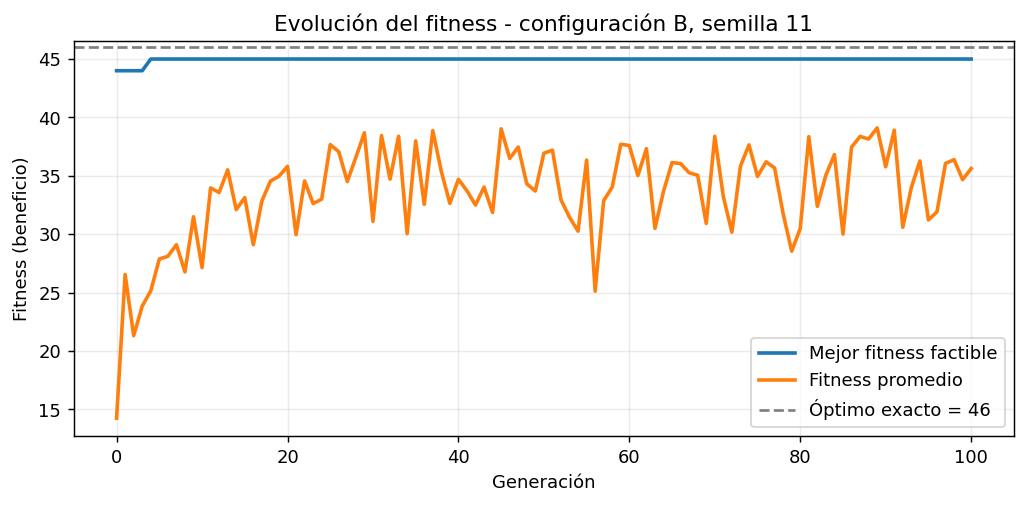

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
fig.set_label("convergencia_demo")
ax.plot(DEMO.hist_mejor, label="Mejor fitness factible", linewidth=2)
ax.plot(DEMO.hist_prom, label="Fitness promedio", linewidth=2)
ax.axhline(OPTIMO, color="gray", linestyle="--", label=f"Óptimo exacto = {OPTIMO}")
ax.set_xlabel("Generación")
ax.set_ylabel("Fitness (beneficio)")
ax.set_title("Evolución del fitness - configuración B, semilla 11")
ax.legend()
fig.tight_layout()
plt.show()

En esta ejecución (configuración B, semilla 11) la mejor solución factible llegó a 45 en la generación 4 y no mejoró después: el algoritmo convergió a una solución de beneficio 45, por debajo del óptimo 46. El fitness promedio sigue oscilando porque la mutación sigue generando individuos nuevos, algunos no factibles (fitness negativo).

## B.4 Experimentos: 3 configuraciones × 5 semillas

In [ ]:
CONFIGS = {"A": dict(poblacion=20, p_cruce=0.7, p_mut=0.01, generaciones=50),
           "B": dict(poblacion=40, p_cruce=0.8, p_mut=0.05, generaciones=100),
           "C": dict(poblacion=60, p_cruce=0.9, p_mut=0.10, generaciones=150)}
SEMILLAS = [11, 23, 37, 49, 61]

EXP: dict[str, list[ResultadoAG]] = {n: [ejecutar_ag(semilla=s, **cfg) for s in SEMILLAS] for n, cfg in CONFIGS.items()}

print(f"Semillas utilizadas: {SEMILLAS}\n")
print(f"{'Config':<7}{'Semilla':>8}  {'Cromosoma':<10}{'Proyectos':<22}{'Costo S/':>9}{'Benef.':>7}{'Saldo S/':>9}{'Gen.':>6}{'t (ms)':>8}")
for n, runs in EXP.items():
    for r in runs:
        print(f"{n:<7}{r.semilla:>8}  {''.join(map(str, r.cromosoma)):<10}{','.join(proyectos(r.cromosoma)):<22}"
              f"{r.costo:>9,}{r.beneficio:>7}{r.saldo:>9,}{r.gen_hallazgo:>6}{r.tiempo * 1000:>8.1f}")

print("\nRESUMEN (5 ejecuciones por configuración)")
print(f"{'Config':<7}{'Mejor':>7}{'Promedio':>10}{'Desv.est.':>11}{'% óptimo':>10}{'Tiempo total (ms)':>19}")
RESUMEN = {}
for n, runs in EXP.items():
    b = np.array([r.beneficio for r in runs])
    RESUMEN[n] = dict(mejor=int(b.max()), prom=float(b.mean()), std=float(b.std()),
                      pct=100.0 * float((b == OPTIMO).mean()), t=sum(r.tiempo for r in runs) * 1000)
    print(f"{n:<7}{b.max():>7}{b.mean():>10.2f}{b.std():>11.3f}{RESUMEN[n]['pct']:>9.0f}%{RESUMEN[n]['t']:>19.1f}")
print(f"\nÓptimo exacto (búsqueda exhaustiva): {OPTIMO}.  Desviación estándar poblacional (ddof=0).")
assert all(r.costo <= PRESUPUESTO for runs in EXP.values() for r in runs), "Una solución reportada excede el presupuesto"

# Ganador global entre las 15 ejecuciones
n_g, GANADOR = max(((n, r) for n, runs in EXP.items() for r in runs), key=lambda t: t[1].beneficio)
print(f"\nMejor solución de las 15 ejecuciones (config {n_g}, semilla {GANADOR.semilla}): {''.join(map(str, GANADOR.cromosoma))} "
      f"-> {proyectos(GANADOR.cromosoma)}, costo S/ {GANADOR.costo:,}, beneficio {GANADOR.beneficio}, saldo S/ {GANADOR.saldo:,}")

Semillas utilizadas: [11, 23, 37, 49, 61]

Config  Semilla  Cromosoma Proyectos              Costo S/ Benef. Saldo S/  Gen.  t (ms)
A            11  00101110  P3,P5,P6,P7              20,000     44        0     0    16.3
A            23  01010110  P2,P4,P6,P7              20,000     45        0     2    14.9
A            37  11010001  P1,P2,P4,P8              19,500     44      500     1    13.6
A            49  11100101  P1,P2,P3,P6,P8           19,500     45      500     0    17.5
A            61  11110100  P1,P2,P3,P4,P6           20,000     46        0    19    23.5
B            11  01010110  P2,P4,P6,P7              20,000     45        0     4    68.6
B            23  01010110  P2,P4,P6,P7              20,000     45        0     0    54.2
B            37  11100010  P1,P2,P3,P7              20,000     45        0     0    51.5
B            49  11110100  P1,P2,P3,P4,P6           20,000     46        0    22    65.0
B            61  11001100  P1,P2,P5,P6              20,000     45  

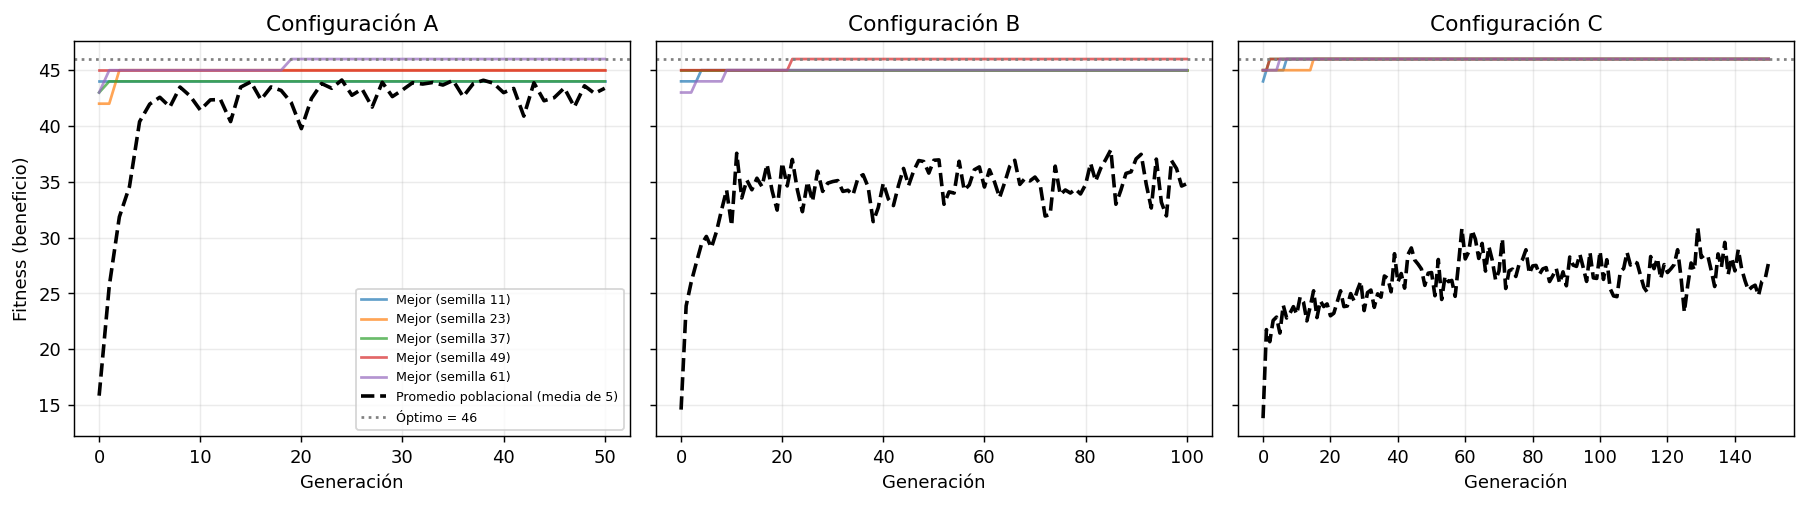

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
fig.set_label("convergencia_configs")
for ax, (n, runs) in zip(ejes, EXP.items()):
    for r in runs:
        ax.plot(r.hist_mejor, alpha=0.7, label=f"Mejor (semilla {r.semilla})")
    ax.plot(np.mean([r.hist_prom for r in runs], axis=0), "k--", linewidth=2, label="Promedio poblacional (media de 5)")
    ax.axhline(OPTIMO, color="gray", linestyle=":", label=f"Óptimo = {OPTIMO}")
    ax.set_title(f"Configuración {n}")
    ax.set_xlabel("Generación")
ejes[0].set_ylabel("Fitness (beneficio)")
ejes[0].legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

### Comparación con la búsqueda exhaustiva

El óptimo exacto es 46. La configuración A alcanzó el óptimo en 20 % de las ejecuciones, la B en 20 % y la C en 100 %. El mejor resultado de las 15 ejecuciones coincide con el óptimo exacto (11110100, beneficio 46, costo S/ 20,000, saldo S/ 0). Ninguna solución reportada excede el presupuesto (verificado con `assert`). Los tiempos son aproximados.

## B.5 Comparación de estrategias de fitness, distancia al óptimo, mutación y elitismo

In [ ]:
max_lineal_no_factible = fitness_lineal(EXACTO["todos"])[~EXACTO["factibles"]].max()
print(f"Con la penalización lineal, el mayor fitness entre las 121 combinaciones no factibles es {max_lineal_no_factible:.1f} (óptimo factible = {OPTIMO})")
print("Comparación de estrategias de fitness (configuración A, 5 semillas)")
print(f"{'Estrategia':<22}{'Gens. sin ningún factible':>27}{'Beneficio promedio':>20}{'% óptimo':>10}")
PEN = {}
for nombre, fn in {"Factibles primero": fitness, "Lineal (lambda=3)": fitness_lineal}.items():
    runs = [ejecutar_ag(semilla=s, fit_fn=fn, **CONFIGS["A"]) for s in SEMILLAS]
    sin_factible = sum(int(np.isnan(r.hist_mejor).sum()) for r in runs)
    b = np.array([r.beneficio for r in runs])
    PEN[nombre] = dict(sin=sin_factible, prom=float(b.mean()), pct=100.0 * float((b == OPTIMO).mean()))
    print(f"{nombre:<22}{sin_factible:>27}{b.mean():>20.2f}{PEN[nombre]['pct']:>9.0f}%")


Con la penalización lineal, el mayor fitness entre las 121 combinaciones no factibles es 45.5 (óptimo factible = 46)
Comparación de estrategias de fitness (configuración A, 5 semillas)
Estrategia              Gens. sin ningún factible  Beneficio promedio  % óptimo
Factibles primero                               0               44.80       20%
Lineal (lambda=3)                              18               44.40        0%


La penalización lineal (beneficio − 3 × exceso en miles de S/) permitía que individuos no factibles obtuvieran un fitness alto (el mayor entre las 256 combinaciones fue 45.5), comparable al de soluciones factibles; en la configuración A hubo 18 generaciones (sumadas en 5 semillas) sin ningún individuo factible en la población (la élite era no factible), y ninguna ejecución alcanzó el óptimo. Con «factibles primero» hubo 0 generaciones sin factibles y 20 % de ejecuciones óptimas.

In [ ]:
OPT = EXACTO["optimos"][0]
print("Genes distintos (distancia de Hamming) entre el resultado de cada ejecución y el óptimo exacto")
HAM = {}
for n, runs in EXP.items():
    HAM[n] = [int(np.sum(r.cromosoma != OPT)) for r in runs]
    print(f"  Configuración {n} (semillas {SEMILLAS}): {HAM[n]}")


Genes distintos (distancia de Hamming) entre el resultado de cada ejecución y el óptimo exacto
  Configuración A (semillas [11, 23, 37, 49, 61]): [5, 3, 3, 2, 0]
  Configuración B (semillas [11, 23, 37, 49, 61]): [3, 3, 3, 0, 3]
  Configuración C (semillas [11, 23, 37, 49, 61]): [0, 0, 0, 0, 0]


In [ ]:
# (1) Efecto de la tasa de mutación: configuración B con p_mut variable, mismas 5 semillas
print("Efecto de la mutación (población 40, cruce 0.8, 100 generaciones)")
print(f"{'p_mut':>6}{'Promedio':>10}{'% óptimo':>10}{'Gen. media hallazgo':>21}")
MUT = {}
for pm in [0.0, 0.01, 0.05, 0.10, 0.30]:
    runs = [ejecutar_ag(40, 0.8, pm, 100, s) for s in SEMILLAS]
    b = np.array([r.beneficio for r in runs])
    MUT[pm] = dict(prom=float(b.mean()), pct=100.0 * float((b == OPTIMO).mean()),
                   gen=float(np.mean([r.gen_hallazgo for r in runs])))
    print(f"{pm:>6.2f}{b.mean():>10.2f}{MUT[pm]['pct']:>9.0f}%{MUT[pm]['gen']:>21.1f}")

# (2) Efecto del elitismo: ¿cuántas veces retrocede el mejor fitness factible entre generaciones?
print("\nEfecto del elitismo (configuración B, 5 semillas)")
ELI = {}
for e in (0, 1):
    retrocesos = 0
    for s in SEMILLAS:
        h = ejecutar_ag(40, 0.8, 0.05, 100, s, elitismo=e).hist_mejor
        retrocesos += int(np.sum(np.diff(h) < 0))
    ELI[e] = retrocesos
    print(f"  elitismo={e}: retrocesos del mejor fitness en {retrocesos} generaciones (de {5 * 100} transiciones)")

Efecto de la mutación (población 40, cruce 0.8, 100 generaciones)
 p_mut  Promedio  % óptimo  Gen. media hallazgo
  0.00     44.40        0%                  0.0
  0.01     44.80        0%                  0.6
  0.05     45.20       20%                  7.0
  0.10     46.00      100%                  6.4
  0.30     46.00      100%                  2.4

Efecto del elitismo (configuración B, 5 semillas)
  elitismo=0: retrocesos del mejor fitness en 11 generaciones (de 500 transiciones)
  elitismo=1: retrocesos del mejor fitness en 0 generaciones (de 500 transiciones)


## B.6 Convergencia prematura y mejoras

**Convergencia prematura.** En la configuración B, 4 de 5 ejecuciones terminaron en soluciones de beneficio 45 y no en el óptimo 46; en la A, 4 de 5 terminaron con beneficio 44-45. Las distancias de Hamming al óptimo fueron A = [5, 3, 3, 2, 0], B = [3, 3, 3, 0, 3] y C = [0, 0, 0, 0, 0]: en B las cuatro ejecuciones fallidas distan exactamente 3 genes del óptimo y en A las fallidas distan entre 2 y 5. Salir de esos óptimos locales exige cambiar varios genes a la vez, y los pasos intermedios pueden exceder el presupuesto (fitness negativo) y se descartan.

**Causas probables:** población pequeña y poco diversa, mutación baja (p = 0.01-0.05), selección por torneo con k = 3 que favorece rápidamente a los mejores y un fitness que expulsa a los no factibles, que son el camino hacia el óptimo. Es una explicación coherente con los experimentos de mutación, pero no se probó cada causa por separado.

**Mejoras propuestas (no evaluadas en este trabajo):** mutación adaptativa que aumente p cuando el mejor fitness se estanca; torneo más pequeño (k = 2) para reducir la presión selectiva; reinicio parcial de la población; o permitir a los no factibles cercanos al presupuesto una penalización más suave.

## B.7 Preguntas de análisis (Parte B)

**¿Cómo afecta la mutación a la convergencia?** Con el resto de parámetros de la configuración B fijos, subir la tasa de mutación mejoró el resultado: con p = 0.00 el beneficio promedio fue 44.40 y ninguna ejecución alcanzó el óptimo (0 %); con 0.01, 44.80 (0 %); con 0.05, 45.20 (20 %); con 0.10, 46.00 (100 %) y con 0.30, 46.00 (100 %). Una mutación muy baja deja a la población atrapada en soluciones por debajo del óptimo; una mayor mantiene diversidad y permite saltar a otra región. El costo es que genera más hijos no factibles, lo que se ve en un fitness promedio poblacional menor en la configuración C (gráfica de convergencia). Estos resultados valen para este problema pequeño y 5 semillas.

**¿Qué aporta el elitismo?** Garantiza que el mejor individuo no se pierda por el cruce o la mutación. En 5 semillas × 100 generaciones de la configuración B, sin elitismo el mejor beneficio factible retrocedió en 11 generaciones; con un élite, en 0. Su riesgo es reducir la diversidad si se preservan demasiados individuos.

**¿Garantiza el algoritmo genético el óptimo global?** No. Es un método heurístico y estocástico. Aquí la configuración A alcanzó el óptimo (46) en 20 % de las ejecuciones y la B en 20 %; solo la C lo hizo en el 100 % con estas 5 semillas, lo que no demuestra que siempre lo logre. Las ejecuciones que no lo alcanzaron quedaron en soluciones factibles de beneficio 44-45 (a 2-5 genes de distancia del óptimo). Solo la búsqueda exhaustiva certifica el óptimo.

**¿Cuándo sería preferible a la búsqueda exhaustiva?** Cuando el número de combinaciones es demasiado grande para enumerarlas. Con 8 proyectos hay 2⁸ = 256 combinaciones y la búsqueda exhaustiva tardó unos 0.19 ms, mucho menos que el algoritmo genético (de unos 10 ms a más de 100 ms por ejecución). Con 40 proyectos habría 2⁴⁰ ≈ 1.1 × 10¹² combinaciones y la enumeración dejaría de ser práctica; allí un algoritmo genético ofrece buenas soluciones aproximadas, sin garantía de optimalidad.

# Análisis integrador

## 17. Lógica difusa frente a algoritmos genéticos

| Aspecto | Lógica difusa (Mamdani) | Algoritmo genético |
|---|---|---|
| Objetivo | Representar conocimiento experto impreciso y producir una decisión o índice | Buscar soluciones de alta calidad en un espacio grande, optimizando un criterio |
| Representación | Variables lingüísticas, funciones de pertenencia y reglas SI-ENTONCES | Cromosomas (aquí, 8 bits) y una función fitness |
| Salida | Un valor numérico desfusificado (índice de riesgo 0-100) | Una solución (subconjunto de proyectos) con su costo y beneficio |
| Naturaleza | Determinista: la misma entrada da la misma salida | Estocástica: depende de la semilla y los parámetros |
| Limitaciones | Los conjuntos y reglas los fija el diseñador; no aprende por sí solo; con muchas variables las reglas crecen rápido | No garantiza el óptimo; exige ajustar parámetros y manejar restricciones; el costo crece con el tamaño del problema |

## 18. Problemas reales

- **Lógica difusa:** Control de climatización de un edificio: temperatura, humedad y ocupación son magnitudes graduales y la experta describe el control con reglas lingüísticas, sin un modelo matemático exacto.
- **Algoritmo genético:** Elaboración de horarios o asignación de rutas de reparto: hay muchas combinaciones posibles, restricciones que cumplir y un costo que minimizar, sin una fórmula directa para el óptimo.

## 19. Sistema híbrido: un algoritmo genético que optimiza un sistema difuso

**Idea.** Un algoritmo genético ajusta los parámetros del sistema de riesgo académico de la Parte A para que reproduzca mejor un conjunto de estudiantes ya evaluados por docentes.

**Cromosoma.** Vector real con los puntos de corte de las funciones de pertenencia (cada conjunto tiene 3 o 4 parámetros, según sea triangular o trapezoidal). Opcionalmente se añaden 18 genes enteros {Bajo, Medio, Alto} con el consecuente de cada regla.

**Fitness.** Minimizar el error cuadrático medio entre el índice difuso y el riesgo asignado por docentes a un conjunto de casos históricos (fitness = 1 / (1 + ECM)), más una penalización por complejidad si se evolucionan las reglas.

**Restricciones.** Los parámetros de cada función deben cumplir a ≤ b ≤ c ≤ d y estar dentro del universo; las etiquetas de cada variable deben mantener el orden Baja < Media < Alta y un traslape mínimo; la base de reglas debe cubrir todo el universo de entradas (verificación de cobertura).

## 20. Evolución hacia un proyecto de Machine Learning

- Con los registros históricos de estudiantes (asistencia, promedio, horas de estudio y si aprobaron o no) se puede plantear un problema de **aprendizaje supervisado**: predecir si un estudiante desaprobará.

- Se dividirían los datos en entrenamiento y prueba, se entrenaría un modelo simple (regresión logística o árbol de decisión) y se evaluaría con exactitud, sensibilidad y matriz de confusión; el índice difuso serviría como línea base y como variable adicional.

- A diferencia del índice difuso, un modelo de clasificación entrenado con datos etiquetados puede estimar una probabilidad, siempre que esté calibrado, y permite estudiar sesgos, validación cruzada y sobreajuste, temas de la Unidad II.

# Declaración de uso de IA y referencias

**Uso de IA generativa.** Se utilizó Claude (Anthropic), un asistente de IA generativa, para organizar el código, redactar borradores del informe y sugerir la estructura del análisis. Todos los resultados numéricos provienen de la ejecución del notebook con semillas fijas; el grupo debe revisar y verificar técnicamente el código y el texto antes de entregarlo, y puede explicar cada función en la sustentación.

**Referencias**

- Deb, K. (2000). An efficient constraint handling method for genetic algorithms. Computer Methods in Applied Mechanics and Engineering, 186(2-4), 311-338.
- Goldberg, D. E. (1989). Genetic Algorithms in Search, Optimization, and Machine Learning. Addison-Wesley.
- Harris, C. R., et al. (2020). Array programming with NumPy. Nature, 585, 357-362.
- Holland, J. H. (1975). Adaptation in Natural and Artificial Systems. University of Michigan Press.
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90-95.
- Mamdani, E. H., & Assilian, S. (1975). An experiment in linguistic synthesis with a fuzzy logic controller. International Journal of Man-Machine Studies, 7(1), 1-13.
- Ross, T. J. (2010). Fuzzy Logic with Engineering Applications (3.ª ed.). Wiley.
- Zadeh, L. A. (1965). Fuzzy sets. Information and Control, 8(3), 338-353.
- Docente del curso (2026). Sesiones 06 y 07: Diseño e implementación de soluciones mediante lógica difusa y algoritmos genéticos. Guía de trabajo grupal, Sistemas Inteligentes 2026-II.